# Car Price Prediction Using Machine Learning

## Objective-  
The objective of this project is to build a machine learning model that predicts the selling price of used cars based on different vehicle features such as model, year, transmission type, fuel type, mileage, engine size, and mileage per gallon (mpg).                             
The performance of multiple regression models will be compared to identify the most accurate model for car price prediction.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
#load the dataset

car_data = pd.read_csv(
    r"D:\Acmegrade training\Jun 26 Day 19 Projects-20260710T165723Z-2-001\Jun 26 Day 19 Projects\PRJ Car Price Prediction\audi.csv"
)

#display first 5 records
car_data.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0


In [3]:
#to check the number of rows and columns

car_data.shape

(10668, 9)

In [4]:
#to display dataset information

car_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10668 entries, 0 to 10667
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         10668 non-null  object 
 1   year          10668 non-null  int64  
 2   price         10668 non-null  int64  
 3   transmission  10668 non-null  object 
 4   mileage       10668 non-null  int64  
 5   fuelType      10668 non-null  object 
 6   tax           10668 non-null  int64  
 7   mpg           10668 non-null  float64
 8   engineSize    10668 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 750.2+ KB


In [5]:
#to check missing values

car_data.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [6]:
#to know the statistical summary of numerical columns

car_data.describe()

,year,price,mileage,tax,mpg,engineSize
count,10668.000000,10668.000000,10668.000000,10668.000000,10668.000000,10668.000000
mean,2017.100675,22896.685039,24827.244001,126.011436,50.770022,1.930709
std,2.167494,11714.841888,23505.257205,67.170294,12.949782,0.602957
min,1997.000000,1490.000000,1.000000,0.000000,18.900000,0.000000
25%,2016.000000,15130.750000,5968.750000,125.000000,40.900000,1.500000
50%,2017.000000,20200.000000,19000.000000,145.000000,49.600000,2.000000
75%,2019.000000,27990.000000,36464.500000,145.000000,58.900000,2.000000
max,2020.000000,145000.000000,323000.000000,580.000000,188.300000,6.300000


In [7]:
#to check duplicate rows

duplicates = car_data.duplicated().sum()

print("Total Duplicate Records :", duplicates)

Total Duplicate Records : 103


In [8]:
#to remove duplicate rows

car_data = car_data.drop_duplicates()

print("Dataset Shape After Removing Duplicates :", car_data.shape)

Dataset Shape After Removing Duplicates : (10565, 9)


In [9]:
#to check unique values
print("Unique Car Models :", car_data["model"].nunique())
print("Transmission Types :", car_data["transmission"].unique())
print("Fuel Types :", car_data["fuelType"].unique())

Unique Car Models : 26
Transmission Types : ['Manual' 'Automatic' 'Semi-Auto']
Fuel Types : ['Petrol' 'Diesel' 'Hybrid']


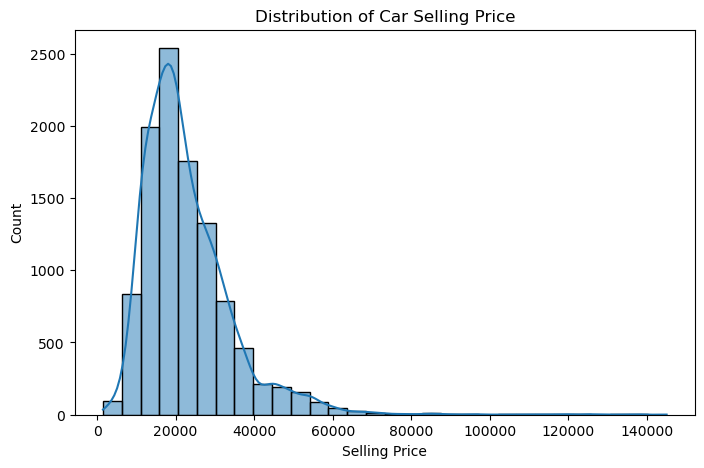

In [10]:
#selling price distribution graph
plt.figure(figsize=(8,5))

sns.histplot(
    car_data["price"],
    bins=30,
    kde=True
)

plt.title("Distribution of Car Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Count")

plt.show()

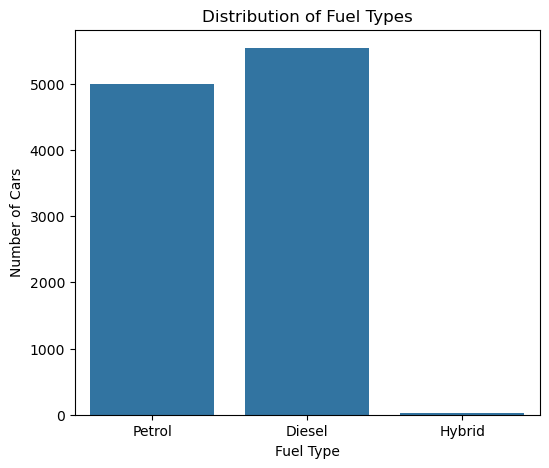

In [11]:
#fuel type count plot
plt.figure(figsize=(6,5))

sns.countplot(
    x="fuelType",
    data=car_data
)

plt.title("Distribution of Fuel Types")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.show()

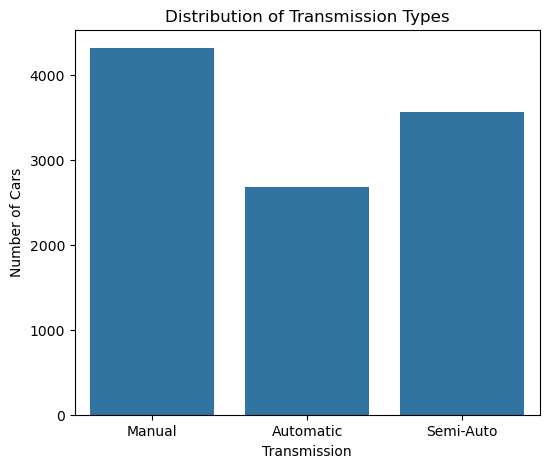

In [12]:
#transmission type count plot
plt.figure(figsize=(6,5))

sns.countplot(
    x="transmission",
    data=car_data
)

plt.title("Distribution of Transmission Types")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")

plt.show()

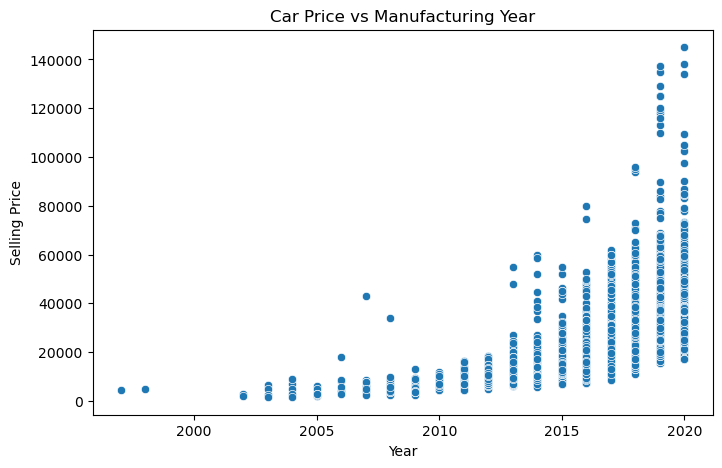

In [13]:
#price vs year graph
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="year",
    y="price",
    data=car_data
)

plt.title("Car Price vs Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Selling Price")

plt.show()

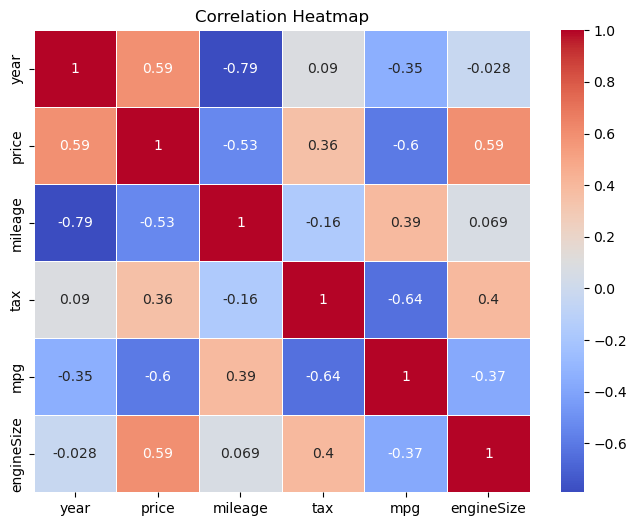

In [14]:
#correlation heatmap
plt.figure(figsize=(8,6))

correlation = car_data.select_dtypes(include=["number"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

In [15]:
# Separate features and target variable

X = car_data.drop("price", axis=1)

Y = car_data["price"]

print("Features Shape :", X.shape)
print("Target Shape :", Y.shape)

Features Shape : (10565, 8)
Target Shape : (10565,)


In [16]:
# Display the first 5 rows of features

X.head()

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize
0,A1,2017,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,Manual,1998,Petrol,145,49.6,1.0


In [17]:
# Convert categorical features into numerical values

X = pd.get_dummies(
    X,
    columns=["model", "transmission", "fuelType"],
    drop_first=True
)

print("Shape After Encoding :", X.shape)

X.head()

Shape After Encoding : (10565, 34)


,year,mileage,tax,mpg,engineSize,model_ A2,model_ A3,model_ A4,model_ A5,model_ A6,...,model_ S4,model_ S5,model_ S8,model_ SQ5,model_ SQ7,model_ TT,transmission_Manual,transmission_Semi-Auto,fuelType_Hybrid,fuelType_Petrol
0,2017,15735,150,55.4,1.4,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
1,2016,36203,20,64.2,2.0,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
2,2016,29946,30,55.4,1.4,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
3,2017,25952,145,67.3,2.0,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,2019,1998,145,49.6,1.0,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,True


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("Training Data :", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data : (8452, 34)
Testing Data : (2113, 34)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape :", X_train.shape)
print("Testing Data Shape :", X_test.shape)

Training Data Shape : (8452, 34)
Testing Data Shape : (2113, 34)


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [22]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)


In [23]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, Y_train)

lr_prediction = lr_model.predict(X_test)

lr_r2 = r2_score(Y_test, lr_prediction)
lr_mae = mean_absolute_error(Y_test, lr_prediction)
lr_rmse = np.sqrt(mean_squared_error(Y_test, lr_prediction))

print("Linear Regression Results")
print("-" * 35)
print("R² Score :", round(lr_r2, 4))
print("MAE      :", round(lr_mae, 2))
print("RMSE     :", round(lr_rmse, 2))

Linear Regression Results
-----------------------------------
R² Score : 0.8841
MAE      : 2627.29
RMSE     : 4050.24


In [24]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(X_train, Y_train)

dt_prediction = dt_model.predict(X_test)

dt_r2 = r2_score(Y_test, dt_prediction)
dt_mae = mean_absolute_error(Y_test, dt_prediction)
dt_rmse = np.sqrt(mean_squared_error(Y_test, dt_prediction))

print("Decision Tree Results")
print("-" * 35)
print("R² Score :", round(dt_r2, 4))
print("MAE      :", round(dt_mae, 2))
print("RMSE     :", round(dt_rmse, 2))

Decision Tree Results
-----------------------------------
R² Score : 0.898
MAE      : 2005.64
RMSE     : 3800.08


In [25]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, Y_train)

rf_prediction = rf_model.predict(X_test)

rf_r2 = r2_score(Y_test, rf_prediction)
rf_mae = mean_absolute_error(Y_test, rf_prediction)
rf_rmse = np.sqrt(mean_squared_error(Y_test, rf_prediction))

print("Random Forest Results")
print("-" * 35)
print("R² Score :", round(rf_r2, 4))
print("MAE      :", round(rf_mae, 2))
print("RMSE     :", round(rf_rmse, 2))

Random Forest Results
-----------------------------------
R² Score : 0.9569
MAE      : 1559.12
RMSE     : 2468.97


In [26]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "R² Score": [
        lr_r2,
        dt_r2,
        rf_r2
    ],
    "MAE": [
        lr_mae,
        dt_mae,
        rf_mae
    ],
    "RMSE": [
        lr_rmse,
        dt_rmse,
        rf_rmse
    ]
})

comparison = comparison.round(4)

comparison

,Model,R² Score,MAE,RMSE
0,Linear Regression,0.8841,2627.2888,4050.2369
1,Decision Tree,0.8980,2005.6374,3800.0785
2,Random Forest,0.9569,1559.1228,2468.9706


In [27]:
best_model = comparison.loc[
    comparison["R² Score"].idxmax(),
    "Model"
]

best_score = comparison["R² Score"].max()

print("=" * 45)
print("MODEL PERFORMANCE SUMMARY")
print("=" * 45)
print(f"Best Model : {best_model}")
print(f"R² Score   : {best_score:.4f}")
print("=" * 45)

MODEL PERFORMANCE SUMMARY
Best Model : Random Forest
R² Score   : 0.9569


In [28]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
3,mpg,0.466177
0,year,0.199666
4,engineSize,0.163119
1,mileage,0.058349
2,tax,0.033647
30,transmission_Manual,0.017502
17,model_ R8,0.013155
33,fuelType_Petrol,0.010435
15,model_ Q7,0.008328
14,model_ Q5,0.004511


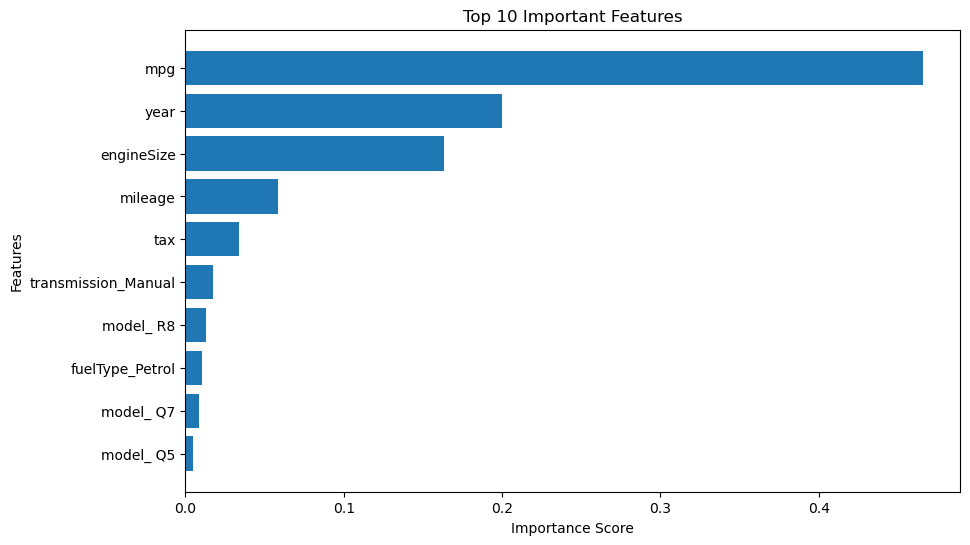

In [29]:
plt.figure(figsize=(10,6))

top_features = feature_importance.head(10)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

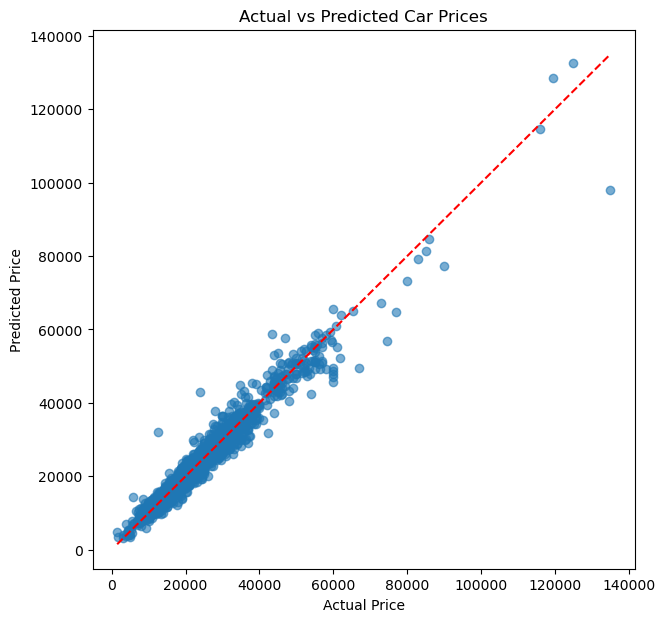

In [30]:
plt.figure(figsize=(7,7))

plt.scatter(
    Y_test,
    rf_prediction,
    alpha=0.6
)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    'r--'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

In [31]:
sample_prediction = rf_model.predict(X_test[:5])

prediction_df = pd.DataFrame({
    "Actual Price": Y_test.iloc[:5].values,
    "Predicted Price": sample_prediction.round(2)
})

prediction_df

,Actual Price,Predicted Price
0,12691,11572.32
1,47816,50943.27
2,21450,20664.66
3,13849,15040.09
4,12990,14183.12


In [32]:
print("=" * 50)
print("CAR PRICE PREDICTION PROJECT SUMMARY")
print("=" * 50)

print(f"Total Records Used : {car_data.shape[0]}")
print(f"Total Features : {X.shape[1]}")
print(f"Best Performing Model : {best_model}")
print(f"Best R² Score : {best_score:.4f}")

print("=" * 50)
print("Project Completed Successfully")
print("=" * 50)

CAR PRICE PREDICTION PROJECT SUMMARY
Total Records Used : 10565
Total Features : 34
Best Performing Model : Random Forest
Best R² Score : 0.9569
Project Completed Successfully


# Conclusion

In this project, multiple machine learning regression models were developed to predict the selling price of used Audi cars.

The dataset was cleaned by removing duplicate records, followed by exploratory data analysis and preprocessing. Categorical variables were encoded before training the models.

Among all the models, the Random Forest Regressor achieved the best performance with the highest R² Score, making it the most suitable model for this dataset.

This project demonstrates how machine learning can be used to estimate car prices accurately using vehicle specifications.